In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LinearRegression, Ridge, Lasso

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from statsmodels.stats.outliers_influence import variance_inflation_factor

In [2]:
url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

df = pd.read_csv(url)

df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
print(df.shape)
df.info()
df.describe()

(20640, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [4]:
print(df.isnull().sum())

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


In [5]:
df["rooms_per_household"] = df["total_rooms"] / df["households"]

df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]

df["population_per_household"] = df["population"] / df["households"]

df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,6.984127,0.146591,2.555556
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,6.238137,0.155797,2.109842
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,8.288136,0.129516,2.802260
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,5.817352,0.184458,2.547945
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,6.281853,0.172096,2.181467


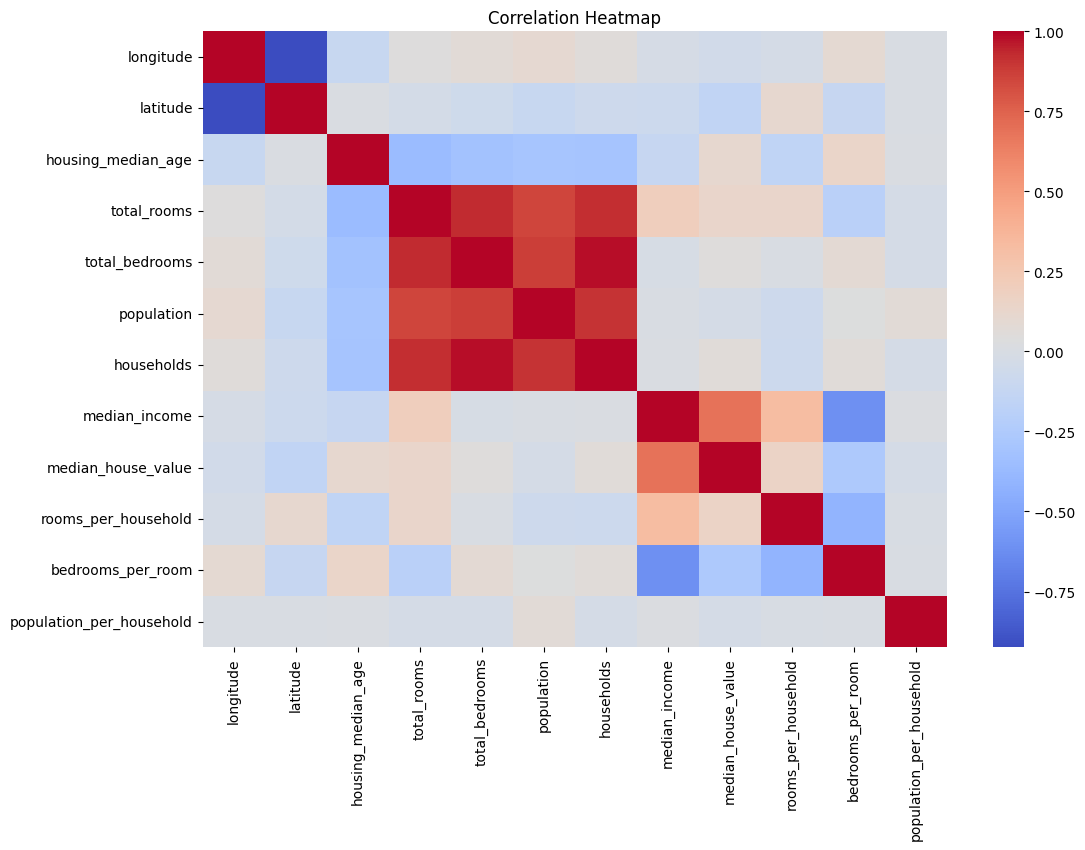

In [6]:
plt.figure(figsize=(12,8))

sns.heatmap(df.corr(numeric_only=True),
            cmap="coolwarm",
            annot=False)

plt.title("Correlation Heatmap")
plt.show()

In [7]:
numeric_df = df.select_dtypes(include=np.number).dropna()

vif = pd.DataFrame()

vif["Feature"] = numeric_df.columns

vif["VIF"] = [variance_inflation_factor(numeric_df.values, i)
              for i in range(numeric_df.shape[1])]

print(vif)

                     Feature        VIF
0                  longitude  10.559725
1                   latitude  11.028063
2         housing_median_age   1.306337
3                total_rooms  18.428689
4             total_bedrooms  48.951908
5                 population   7.283165
6                 households  44.643455
7              median_income   3.499982
8         median_house_value   2.830645
9        rooms_per_household   1.711897
10         bedrooms_per_room   2.807362
11  population_per_household   1.064447


In [8]:
X = df.drop("median_house_value", axis=1)

y = df["median_house_value"]

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [10]:
num_cols = X.select_dtypes(include=np.number).columns

cat_cols = X.select_dtypes(include="object").columns

In [11]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, num_cols),
    ("cat", categorical_transformer, cat_cols)
])

In [12]:
ols = Pipeline([
    ("prep", preprocessor),
    ("model", LinearRegression())
])

ols.fit(X_train, y_train)

ols_pred = ols.predict(X_test)

In [13]:
ridge_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", Ridge())
])

ridge_params = {
    "model__alpha":[0.01,0.1,1,10,100]
}

ridge_grid = GridSearchCV(
    ridge_pipe,
    ridge_params,
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

ridge_grid.fit(X_train,y_train)

ridge_pred = ridge_grid.predict(X_test)

print("Best Alpha:", ridge_grid.best_params_)

Best Alpha: {'model__alpha': 1}


In [14]:
lasso_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", Lasso(max_iter=5000))
])

lasso_params = {
    "model__alpha":[0.001,0.01,0.1,1,10]
}

lasso_grid = GridSearchCV(
    lasso_pipe,
    lasso_params,
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

lasso_grid.fit(X_train,y_train)

lasso_pred = lasso_grid.predict(X_test)

print("Best Alpha:", lasso_grid.best_params_)

Best Alpha: {'model__alpha': 1}


In [15]:
def evaluate(y_true,y_pred):

    rmse=np.sqrt(mean_squared_error(y_true,y_pred))

    mae=mean_absolute_error(y_true,y_pred)

    r2=r2_score(y_true,y_pred)

    return rmse,mae,r2

In [16]:
ols_result = evaluate(y_test, ols_pred)

ridge_result = evaluate(y_test, ridge_pred)

lasso_result = evaluate(y_test, lasso_pred)

results = pd.DataFrame({
    "Model":["OLS","Ridge","Lasso"],
    "RMSE":[ols_result[0],ridge_result[0],lasso_result[0]],
    "MAE":[ols_result[1],ridge_result[1],lasso_result[1]],
    "R2":[ols_result[2],ridge_result[2],lasso_result[2]]
})

results

,Model,RMSE,MAE,R2
0,OLS,69127.038299,49645.492445,0.635339
1,Ridge,69134.965274,49652.142873,0.635256
2,Lasso,69128.091241,49646.428893,0.635328


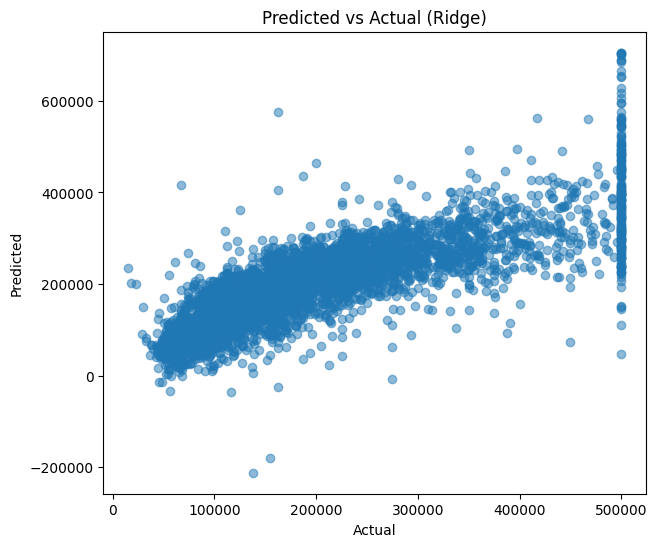

In [17]:
plt.figure(figsize=(7,6))

plt.scatter(y_test,
            ridge_pred,
            alpha=0.5)

plt.xlabel("Actual")

plt.ylabel("Predicted")

plt.title("Predicted vs Actual (Ridge)")

plt.show()

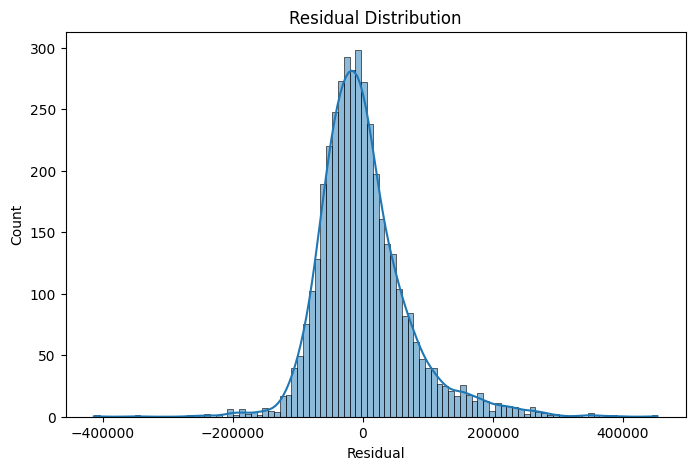

In [18]:
residuals = y_test - ridge_pred

plt.figure(figsize=(8,5))

sns.histplot(residuals,
             kde=True)

plt.title("Residual Distribution")

plt.xlabel("Residual")

plt.show()

In [21]:
print("=== Regression Model Performance Summary ===\n")
best_model = results.sort_values("RMSE")
print(best_model.to_string(index=False))

print("\n=== Best Hyperparameters ===")
print(f"Ridge Best Alpha: {ridge_grid.best_params_['model__alpha']}")
print(f"Lasso Best Alpha: {lasso_grid.best_params_['model__alpha']}")

print("\n=== Conclusion ===")
best_model_name = best_model.iloc[0]['Model']
best_rmse = best_model.iloc[0]['RMSE']
best_r2 = best_model.iloc[0]['R2']
print(f"The best performing model is {best_model_name} with an RMSE of {best_rmse:.2f} and an R2 score of {best_r2:.4f}.")

=== Regression Model Performance Summary ===

Model         RMSE          MAE       R2
  OLS 69127.038299 49645.492445 0.635339
Lasso 69128.091241 49646.428893 0.635328
Ridge 69134.965274 49652.142873 0.635256

=== Best Hyperparameters ===
Ridge Best Alpha: 1
Lasso Best Alpha: 1

=== Conclusion ===
The best performing model is OLS with an RMSE of 69127.04 and an R2 score of 0.6353.
